# Demo: Dự đoán giá nhà bằng Hồi quy tuyến tính

Mỗi căn nhà được mô tả bởi 3 đặc trưng:

| Ký hiệu | Đặc trưng | Cột dữ liệu | Đơn vị |
|---|---|---|---|
| $x_1$ | Diện tích | `dien_tich` | m² |
| $x_2$ | Số phòng ngủ | `so_phong_ngu` | phòng |
| $x_3$ | Khoảng cách tới trung tâm | `khoang_cach` | km |
| $y$ | Giá nhà | `gia` | triệu VND |

Mô hình: $\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3 = \bar{\mathbf{x}}^T \bar{\mathbf{w}}$

Dữ liệu mẫu gồm **1000 căn nhà** trong file `data/gia_nha.csv` (sinh bởi `data/tao_du_lieu.py`).

## 1. Đọc và khám phá dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/gia_nha.csv')
print('Kich thuoc du lieu:', df.shape)
df.head()

Kich thuoc du lieu: (1000, 4)


,dien_tich,so_phong_ngu,khoang_cach,gia
0,93.7,2,24.3,2524.0
1,191.6,4,8.6,6195.0
2,154.4,4,12.3,4981.0
3,131.8,4,5.3,4753.0
4,56.5,2,15.5,1820.0


In [2]:
df.describe()

,dien_tich,so_phong_ngu,khoang_cach,gia
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,113.342600,2.940000,12.574400,3589.155000
std,49.663234,1.373421,7.072082,1762.812232
min,30.800000,1.000000,0.500000,300.000000
25%,70.100000,2.000000,6.700000,2043.500000
50%,114.450000,3.000000,12.450000,3596.000000
75%,156.550000,4.000000,18.600000,4991.250000
max,200.000000,6.000000,24.900000,7513.000000


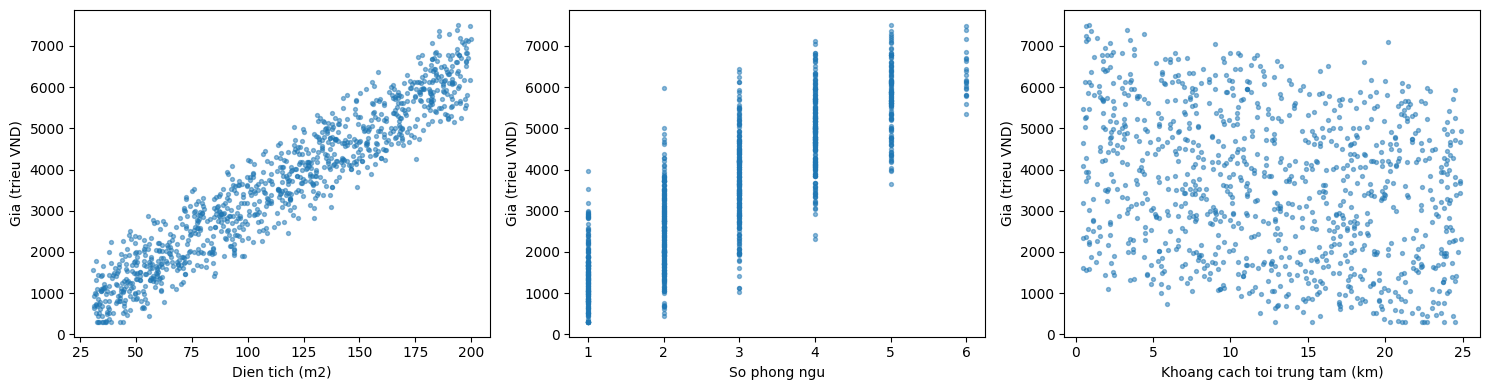

In [3]:
# Quan he giua tung dac trung va gia nha
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cot = ['dien_tich', 'so_phong_ngu', 'khoang_cach']
ten = ['Dien tich (m2)', 'So phong ngu', 'Khoang cach toi trung tam (km)']
for ax, c, t in zip(axes, cot, ten):
    ax.scatter(df[c], df['gia'], s=8, alpha=0.5)
    ax.set_xlabel(t)
    ax.set_ylabel('Gia (trieu VND)')
plt.tight_layout()
plt.show()

In [4]:
# He so tuong quan giua cac bien
df.corr().round(3)

,dien_tich,so_phong_ngu,khoang_cach,gia
dien_tich,1.000,0.853,-0.026,0.953
so_phong_ngu,0.853,1.000,-0.013,0.846
khoang_cach,-0.026,-0.013,1.000,-0.265
gia,0.953,0.846,-0.265,1.000


**Nhận xét:** giá nhà **tăng** theo diện tích và số phòng ngủ, **giảm** khi xa trung tâm.
Diện tích và số phòng ngủ tương quan khá mạnh với nhau (nhà rộng thường nhiều phòng hơn).

## 2. Chia tập huấn luyện / kiểm tra (80% / 20%)

In [5]:
from sklearn.model_selection import train_test_split

X = df[['dien_tich', 'so_phong_ngu', 'khoang_cach']].values   # moi hang la mot mau
y = df['gia'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Tap huan luyen:', X_train.shape, ' Tap kiem tra:', X_test.shape)

Tap huan luyen: (800, 3)  Tap kiem tra: (200, 3)


## 3. Nghiệm theo công thức (Normal Equation)

$$\bar{\mathbf{w}} = (\bar{\mathbf{X}}^T \bar{\mathbf{X}})^{\dagger} \bar{\mathbf{X}}^T \mathbf{y}$$

trong đó $\bar{\mathbf{X}}$ là $\mathbf{X}$ được thêm cột toàn số 1 ở đầu.

In [6]:
# Tao ma tran Xbar (them cot 1 vao truoc ma tran X)
one = np.ones((X_train.shape[0], 1))
Xbar = np.concatenate((one, X_train), axis=1)

# w = (Xbar^T Xbar)^+ Xbar^T y
A = Xbar.T @ Xbar
b = Xbar.T @ y_train
w = np.linalg.pinv(A) @ b

print('w0 (he so chech)   = %.4f' % w[0])
print('w1 (dien tich)     = %.4f' % w[1])
print('w2 (so phong ngu)  = %.4f' % w[2])
print('w3 (khoang cach)   = %.4f' % w[3])

w0 (he so chech)   = 494.5219
w1 (dien tich)     = 29.4389
w2 (so phong ngu)  = 175.4041
w3 (khoang cach)   = -60.2369


**Ý nghĩa các hệ số** (dữ liệu được sinh với $w_0=500,\ w_1=30,\ w_2=150,\ w_3=-60$):
- $w_1$: mỗi m² tăng thêm làm giá tăng khoảng $w_1$ triệu.
- $w_2$: mỗi phòng ngủ thêm làm giá tăng khoảng $w_2$ triệu.
- $w_3 < 0$: mỗi km xa trung tâm hơn làm giá giảm khoảng $|w_3|$ triệu.

## 4. Sử dụng thư viện scikit-learn

In [7]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print('Ket qua tu scikit-learn:')
print('  w0 =', round(model.intercept_, 4))
print('  w1, w2, w3 =', np.round(model.coef_, 4))
print('Ket qua tinh thu cong:')
print('  w0 =', round(w[0], 4))
print('  w1, w2, w3 =', np.round(w[1:], 4))

Ket qua tu scikit-learn:
  w0 = 494.5219
  w1, w2, w3 = [ 29.4389 175.4041 -60.2369]
Ket qua tinh thu cong:
  w0 = 494.5219
  w1, w2, w3 = [ 29.4389 175.4041 -60.2369]


## 5. Giải bằng Gradient Descent

$$\mathbf{w} \leftarrow \mathbf{w} - \frac{\eta}{N} \bar{\mathbf{X}}^T (\bar{\mathbf{X}}\mathbf{w} - \mathbf{y})$$

Các đặc trưng có thang đo rất khác nhau (diện tích ~100, số phòng ~3), nên cần **chuẩn hóa** (standardization) để Gradient Descent hội tụ nhanh:
$x' = \dfrac{x - \mu}{\sigma}$. Sau khi huấn luyện, ta đổi trọng số về thang đo gốc để so sánh.

Gradient Descent: w0 = 494.5770, w1, w2, w3 = [ 29.433  175.616  -60.2378]
Normal Equation : w0 = 494.5219, w1, w2, w3 = [ 29.4389 175.4041 -60.2369]


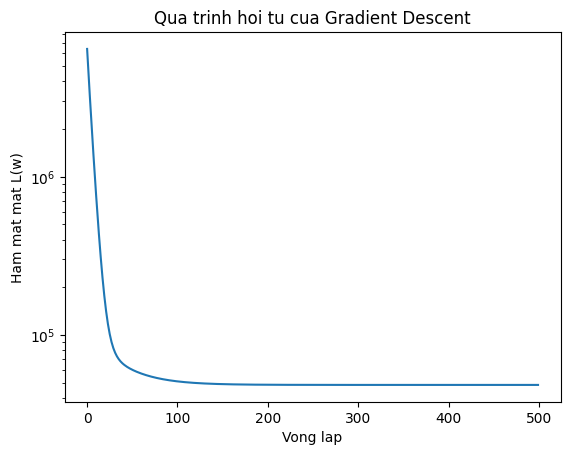

In [8]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
Xs = (X_train - mu) / sigma
Xs_bar = np.concatenate((np.ones((Xs.shape[0], 1)), Xs), axis=1)

def loss(w, Xb, y):
    e = y - Xb @ w
    return (e @ e) / (2 * len(y))

eta = 0.1
w_gd = np.zeros(Xs_bar.shape[1])
lich_su = []
for it in range(500):
    grad = Xs_bar.T @ (Xs_bar @ w_gd - y_train) / len(y_train)
    w_gd = w_gd - eta * grad
    lich_su.append(loss(w_gd, Xs_bar, y_train))

# Doi trong so ve thang do goc
w_goc = w_gd[1:] / sigma
w0_goc = w_gd[0] - np.sum(w_gd[1:] * mu / sigma)
print('Gradient Descent: w0 = %.4f, w1, w2, w3 =' % w0_goc, np.round(w_goc, 4))
print('Normal Equation : w0 = %.4f, w1, w2, w3 =' % w[0], np.round(w[1:], 4))

plt.plot(lich_su)
plt.xlabel('Vong lap')
plt.ylabel('Ham mat mat L(w)')
plt.yscale('log')
plt.title('Qua trinh hoi tu cua Gradient Descent')
plt.show()

## 6. Đánh giá mô hình trên tập kiểm tra

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print('MAE  = %.2f trieu' % mean_absolute_error(y_test, y_pred))
print('MSE  = %.2f' % mse)
print('RMSE = %.2f trieu' % np.sqrt(mse))
print('R^2  = %.4f' % r2_score(y_test, y_pred))

MAE  = 233.73 trieu
MSE  = 80698.89
RMSE = 284.08 trieu
R^2  = 0.9720


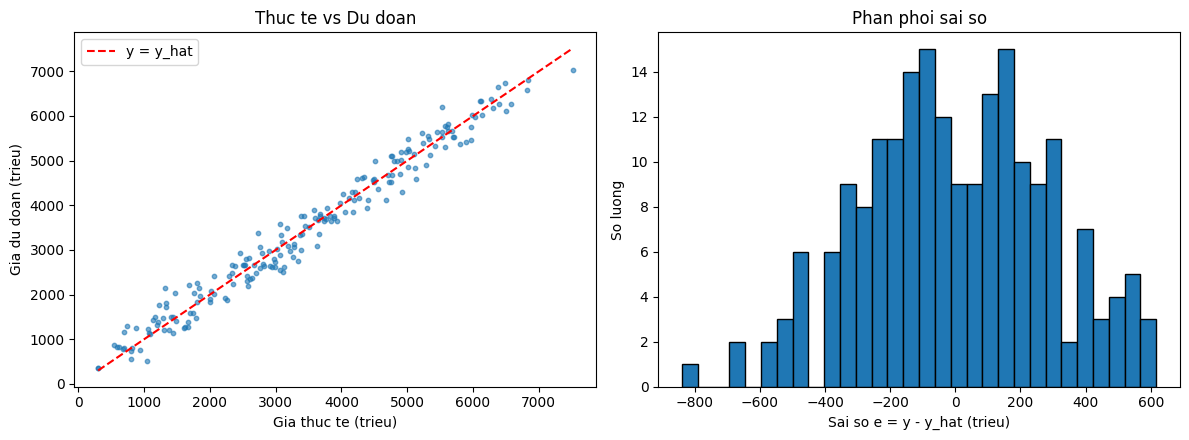

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gia thuc te vs gia du doan
axes[0].scatter(y_test, y_pred, s=10, alpha=0.6)
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, 'r--', label='y = y_hat')
axes[0].set_xlabel('Gia thuc te (trieu)')
axes[0].set_ylabel('Gia du doan (trieu)')
axes[0].set_title('Thuc te vs Du doan')
axes[0].legend()

# Phan phoi sai so
axes[1].hist(y_test - y_pred, bins=30, edgecolor='k')
axes[1].set_xlabel('Sai so e = y - y_hat (trieu)')
axes[1].set_ylabel('So luong')
axes[1].set_title('Phan phoi sai so')
plt.tight_layout()
plt.show()

## 7. Dự đoán giá cho căn nhà mới

In [11]:
nha_moi = pd.DataFrame({
    'dien_tich':    [60, 100, 150],
    'so_phong_ngu': [2, 3, 4],
    'khoang_cach':  [3, 10, 20],
})
nha_moi['gia_du_doan (trieu)'] = np.round(model.predict(nha_moi.values), 1)
nha_moi

,dien_tich,so_phong_ngu,khoang_cach,gia_du_doan (trieu)
0,60,2,3,2431.0
1,100,3,10,3362.3
2,150,4,20,4407.2


## 8. Hồi quy Ridge và Lasso

Diện tích và số phòng ngủ tương quan mạnh (đa cộng tuyến). Ta so sánh hệ số của 3 mô hình.

In [12]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=10.0).fit(X_train, y_train)
lasso = Lasso(alpha=10.0).fit(X_train, y_train)

ket_qua = pd.DataFrame({
    'Linear': np.r_[model.intercept_, model.coef_],
    'Ridge':  np.r_[ridge.intercept_, ridge.coef_],
    'Lasso':  np.r_[lasso.intercept_, lasso.coef_],
}, index=['w0', 'w1 (dien tich)', 'w2 (so phong)', 'w3 (khoang cach)']).round(3)
print(ket_qua)

for ten, m in [('Linear', model), ('Ridge', ridge), ('Lasso', lasso)]:
    p = m.predict(X_test)
    print('%-6s: RMSE = %.2f, R^2 = %.4f' % (ten, np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)))

                   Linear    Ridge    Lasso
w0                494.522  495.339  496.922
w1 (dien tich)     29.439   29.533   29.869
w2 (so phong)     175.404  171.391  156.982
w3 (khoang cach)  -60.237  -60.214  -60.003
Linear: RMSE = 284.08, R^2 = 0.9720
Ridge : RMSE = 283.73, R^2 = 0.9721
Lasso : RMSE = 282.70, R^2 = 0.9723


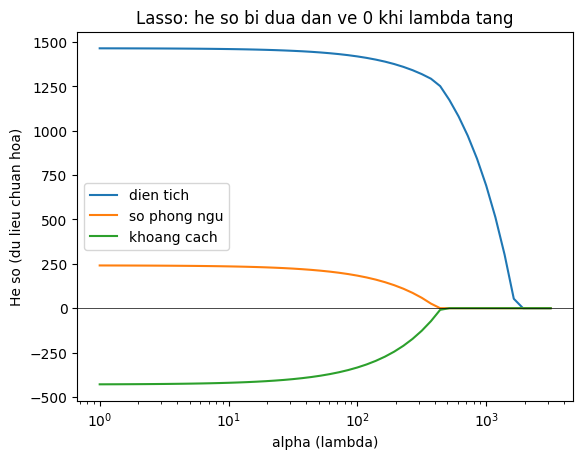

In [13]:
# Anh huong cua lambda (alpha) len he so Lasso - tren du lieu da chuan hoa
from sklearn.preprocessing import StandardScaler
Xs_train = StandardScaler().fit_transform(X_train)

alphas = np.logspace(0, 3.5, 50)
coefs = np.array([Lasso(alpha=a).fit(Xs_train, y_train).coef_ for a in alphas])

for j, t in enumerate(['dien tich', 'so phong ngu', 'khoang cach']):
    plt.plot(alphas, coefs[:, j], label=t)
plt.xscale('log')
plt.xlabel('alpha (lambda)')
plt.ylabel('He so (du lieu chuan hoa)')
plt.title('Lasso: he so bi dua dan ve 0 khi lambda tang')
plt.axhline(0, color='k', lw=0.5)
plt.legend()
plt.show()

## 9. Kết luận

- Hồi quy tuyến tính khôi phục khá sát các hệ số thật dùng để sinh dữ liệu.
- Normal Equation, scikit-learn và Gradient Descent cho **cùng một nghiệm**.
- $R^2$ gần 1 cho thấy mô hình tuyến tính giải thích tốt phần lớn biến thiên của giá nhà; phần sai số còn lại là do **nhiễu** trong dữ liệu.
- Khi $\lambda$ tăng, Lasso đưa dần các hệ số kém quan trọng về **0** (lựa chọn đặc trưng).